In [1]:
# Bibliothèques de base
import pyodbc
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns


C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
# Connexion à la base de données
conn_str = (
    "Driver={ODBC Driver 17 for SQL Server};"
    "Server=LAPTOP-GPVK1ANC;"  # Remplacez par votre serveur
    "Database=DW_SupplyChain;"
    "Trusted_Connection=yes;"
)
cnxn = pyodbc.connect(conn_str)

# Requête SQL pour extraire les données nécessaires
query = """
SELECT 
    productFK,
    brandFK,
    Production_Start_Time,
    Production_End_Time,
    manufacturedate,
    expirydate,
    Dosage,
    quantityused
FROM fact_production
"""
# Chargement des données dans un DataFrame
df = pd.read_sql(query, cnxn)

# Vérification des premières lignes du DataFrame
df.head()


C:\Users\ayadi\AppData\Local\Temp\ipykernel_11312\1517602925.py:24: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, cnxn)


,productFK,brandFK,Production_Start_Time,Production_End_Time,manufacturedate,expirydate,Dosage,quantityused
0,2,15,2022032723,2022032800,2024082023,2025083023,9,9
1,2,15,2022040823,2022040806,2024082023,2025083023,9,9
2,2,15,2022050523,2022050517,2024082023,2025083023,9,9
3,2,15,2022052123,2022052119,2024082023,2025083023,9,9
4,2,15,2022070123,2022070113,2024082023,2025083023,9,9


In [8]:
# Conversion de Production_Start_Time en datetime
df['Production_Start_Time'] = pd.to_datetime(df['Production_Start_Time'].astype(str), format='%Y%m%d%H')


# Affichage des premières lignes
df.head()


KeyError: 'Production_Start_Time'

In [7]:
# Vérification des valeurs manquantes
print(df.isnull().sum())

# Suppression des lignes contenant des valeurs manquantes
df = df.dropna()

# Conversion des dates en format datetime
df['Production_Start_Time'] = pd.to_datetime(df['Production_Start_Time'], unit='ms')
df['Production_End_Time'] = pd.to_datetime(df['Production_End_Time'], unit='ms')

# Calcul de la durée de production
df['Production_Duration'] = (df['Production_End_Time'] - df['Production_Start_Time']).dt.total_seconds()

# Sélection des caractéristiques et de la cible
X = df[['productFK', 'brandFK', 'Production_Duration', 'manufacturedate', 'expirydate', 'Dosage']]
y = df['quantityused']

# Vérification des premières lignes après nettoyage
df.head()


productFK              0
brandFK                0
Starttimeprod          0
Production_End_Time    0
manufacturedate        0
expirydate             0
Dosage                 0
quantityused           0
dtype: int64


KeyError: 'Production_Start_Time'

In [4]:
# Division des données en ensemble d'entraînement et de test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Normalisation des caractéristiques
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Vérification de la normalisation
print("Moyenne des données d'entraînement après normalisation :", np.mean(X_train_scaled, axis=0))
print("Écart-type des données d'entraînement après normalisation :", np.std(X_train_scaled, axis=0))


Moyenne des données d'entraînement après normalisation : [ 3.11806603e-17  4.08574169e-17  1.34399398e-18  8.89163567e-13
 -1.06713122e-16 -1.09401110e-16]
Écart-type des données d'entraînement après normalisation : [1. 1. 1. 1. 1. 1.]


In [5]:
# Entraînement du modèle de régression linéaire
model = LinearRegression()
model.fit(X_train_scaled, y_train)

# Prédiction sur les données de test
y_pred = model.predict(X_test_scaled)

# Affichage des coefficients du modèle
print("Coefficients du modèle :", model.coef_)


Coefficients du modèle : [ 6.07952903e-03  9.07743813e-03 -1.77227551e-04 -3.08861008e-02
 -1.37165321e-02  2.86963494e+00]


Erreur quadratique moyenne (MSE) :  0.3419989378157524
R² :  0.9593305309008245


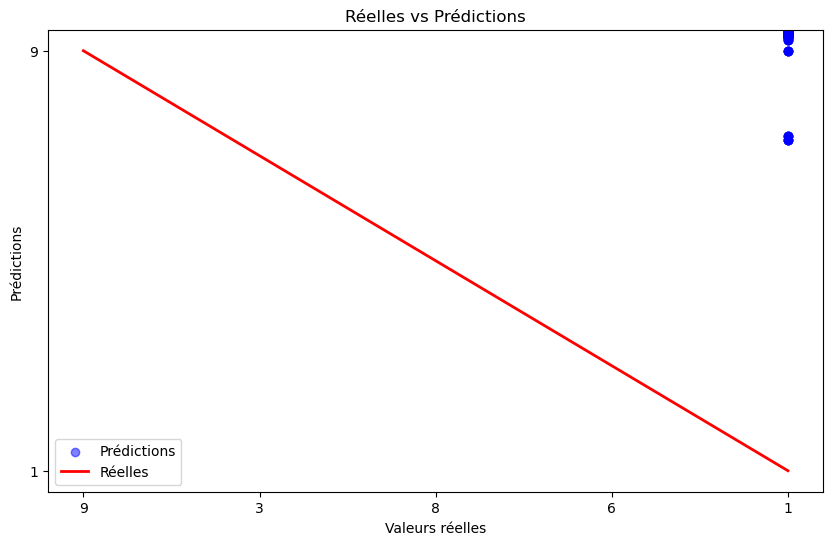

In [7]:
# Calcul des métriques d'évaluation
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Affichage des résultats
print("Erreur quadratique moyenne (MSE) : ", mse)
print("R² : ", r2)

# Visualisation des prédictions vs valeurs réelles
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, color='blue', alpha=0.5, label='Prédictions')  # Bleu pour les prédictions
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linewidth=2, label='Réelles')  # Rouge pour la ligne idéale
plt.xlabel("Valeurs réelles")
plt.ylabel("Prédictions")
plt.title("Réelles vs Prédictions")
plt.legend()  # Ajouter la légende pour les explications
plt.show()
